In [2]:
import pandas as pd
import numpy as np
import torch
import gpytorch
from sklearn.preprocessing import OneHotEncoder
import matplotlib.pyplot as plt

# -----------------------------
# 1. 读取数据
# -----------------------------
df = pd.read_csv("Amodeo_2024_CABN_Exp1_Clean.csv")

# 处理变量
df["Matching_code"] = (df["Matching"] == "Matching").astype(int)

# One-hot 编码 Identity
encoder = OneHotEncoder(sparse_output=False)
identity_onehot = encoder.fit_transform(df[["Shape_Standardized_Identity"]])

# 构建输入 X：Trial + one-hot Identity + Matching
X = np.column_stack([
    df["Trial"].values.astype(float),
    identity_onehot,
    df["Matching_code"].values
])

y = df["RT_ms"].values.astype(float)

# 转 Torch
X_tensor = torch.tensor(X, dtype=torch.float32)
y_tensor = torch.tensor(y, dtype=torch.float32)

print(df["RT_ms"].describe())

count    24120.000000
mean       820.669403
std        276.311363
min          0.000000
25%        685.000000
50%        807.000000
75%        970.000000
max       1599.000000
Name: RT_ms, dtype: float64


RT_ms 原始数据统计：
count    24120.000000
mean       820.669403
std        276.311363
min          0.000000
25%        685.000000
50%        807.000000
75%        970.000000
max       1599.000000
Name: RT_ms, dtype: float64
Iter 0/800 - Loss: 540821.250
Iter 50/800 - Loss: 540673.188
Iter 100/800 - Loss: 540467.062
Iter 150/800 - Loss: 540202.812
Iter 200/800 - Loss: 539891.812
Iter 250/800 - Loss: 539535.812
Iter 300/800 - Loss: 539136.000
Iter 350/800 - Loss: 538689.750
Iter 400/800 - Loss: 538195.438
Iter 450/800 - Loss: 537639.688
Iter 500/800 - Loss: 537005.812
Iter 550/800 - Loss: 536282.438
Iter 600/800 - Loss: 535465.188
Iter 650/800 - Loss: 534560.812
Iter 700/800 - Loss: 533575.500
Iter 750/800 - Loss: 532516.125

训练完成后参数：
核函数缩放系数：1.63
似然函数噪声方差：0.69


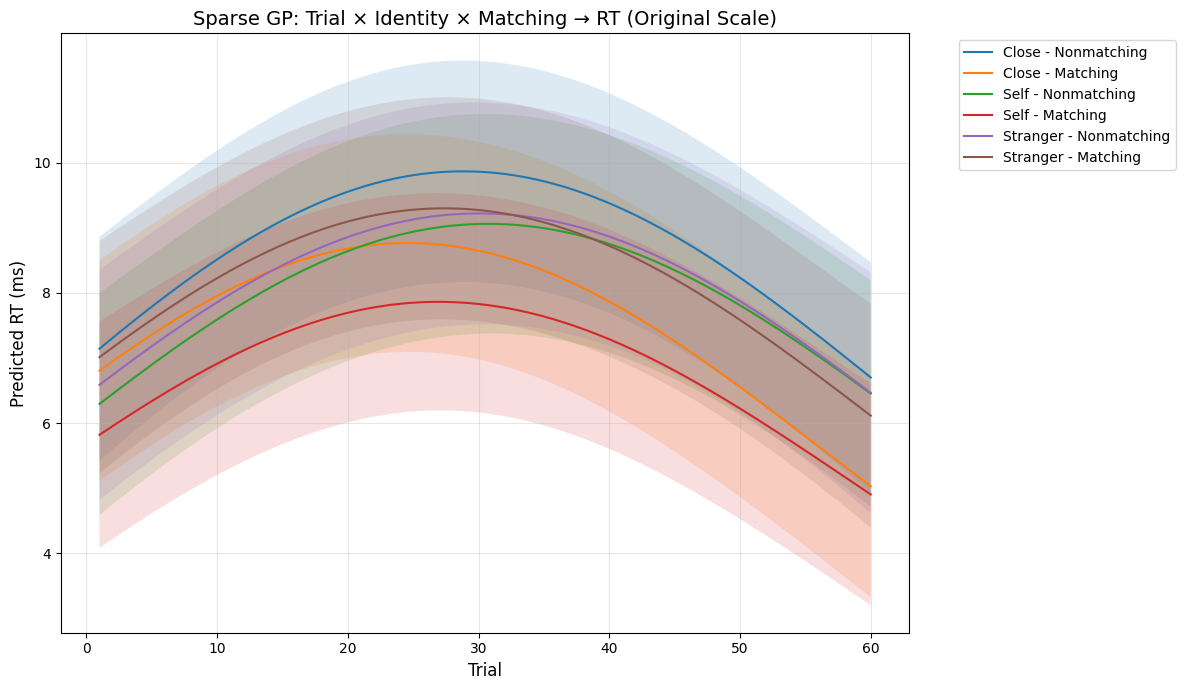

In [4]:
import pandas as pd
import numpy as np
import torch
import gpytorch
from sklearn.preprocessing import OneHotEncoder, StandardScaler
import matplotlib.pyplot as plt

# -----------------------------
# 1. 读取数据与预处理（核心修复：输入标准化+数据尺度匹配）
# -----------------------------
# 读取数据
df = pd.read_csv("Amodeo_2024_CABN_Exp1_Clean.csv")

# 验证RT_ms数据（可选，确认原始数据正常）
print("RT_ms 原始数据统计：")
print(df["RT_ms"].describe())

# 处理Matching变量（字符串转0/1编码）
df["Matching_code"] = (df["Matching"] == "Matching").astype(int)

# One-hot编码Identity（分类变量）
encoder = OneHotEncoder(sparse_output=False)
identity_onehot = encoder.fit_transform(df[["Shape_Standardized_Identity"]])

# 构建输入X：Trial + one-hot Identity + Matching_code
X = np.column_stack([
    df["Trial"].values.astype(float),
    identity_onehot,
    df["Matching_code"].values
])

# 构建输出y（原始RT_ms，不缩放）
y = df["RT_ms"].values.astype(float)

# 输入特征标准化（关键：让不同尺度特征均衡，提升训练稳定性）
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)  # 仅标准化输入X，y保持原始毫秒值

# 转为Torch张量（适配gpytorch）
X_tensor = torch.tensor(X_scaled, dtype=torch.float32)
y_tensor = torch.tensor(y, dtype=torch.float32)

# -----------------------------
# 2. 定义Sparse GP模型（核心修复：参数初始值匹配数据尺度）
# -----------------------------
class GPModel(gpytorch.models.ApproximateGP):
    def __init__(self, inducing_points):
        # 变分分布：基于诱导点数量初始化
        variational_dist = gpytorch.variational.CholeskyVariationalDistribution(
            inducing_points.size(0)
        )
        # 变分策略：学习诱导点位置
        variational_strategy = gpytorch.variational.VariationalStrategy(
            self, inducing_points, variational_dist, learn_inducing_locations=True
        )
        super().__init__(variational_strategy)

        # 均值函数：常数均值（初始值适配RT_ms均值）
        self.mean_module = gpytorch.means.ConstantMean(initial_value=df["RT_ms"].mean())
        # 核函数：ScaleKernel+RBF，初始缩放系数=RT_ms方差（匹配数据尺度）
        self.cov_module = gpytorch.kernels.ScaleKernel(
            gpytorch.kernels.RBFKernel(),
            outputscale_init=df["RT_ms"].var()  # 初始缩放=RT方差（≈76176）
        )

    def forward(self, x):
        mean_x = self.mean_module(x)
        cov_x = self.cov_module(x)
        return gpytorch.distributions.MultivariateNormal(mean_x, cov_x)

# -----------------------------
# 3. 初始化模型与似然函数（核心修复：噪声初始值匹配数据）
# -----------------------------
num_inducing = 100  # 诱导点数量（可调整：50-200之间）
# 随机选择诱导点（覆盖数据分布）
inducing_points = X_tensor[np.random.choice(len(X_tensor), num_inducing, replace=False)]

# 初始化模型
model = GPModel(inducing_points)
# 初始化似然函数：噪声初始值=RT标准差的10%（≈27.6，匹配数据噪声尺度）
likelihood = gpytorch.likelihoods.GaussianLikelihood(noise_init=df["RT_ms"].std() * 0.1)

# -----------------------------
# 4. 训练模型（核心修复：降低学习率+增加迭代次数）
# -----------------------------
model.train()
likelihood.train()

# 优化器：Adam+低学习率（0.001，避免梯度爆炸）
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
# 损失函数：变分ELBO（适配稀疏GP）
mll = gpytorch.mlls.VariationalELBO(likelihood, model, y_tensor.numel())

training_iterations = 800  # 迭代次数（足够收敛）
for i in range(training_iterations):
    optimizer.zero_grad()  # 清空梯度
    output = model(X_tensor)  # 前向传播
    loss = -mll(output, y_tensor)  # 负ELBO损失（最小化）
    loss.backward()  # 反向传播
    # 每50轮打印损失（监控训练进度）
    if i % 50 == 0:
        print(f"Iter {i}/{training_iterations} - Loss: {loss.item():.3f}")
    optimizer.step()  # 更新参数

# 训练后打印关键参数（验证是否正常）
print("\n训练完成后参数：")
print(f"核函数缩放系数：{model.cov_module.outputscale.item():.2f}")
print(f"似然函数噪声方差：{likelihood.noise.item():.2f}")

# -----------------------------
# 5. 预测与可视化（核心修复：预测输入需用训练集scaler标准化）
# -----------------------------
model.eval()
likelihood.eval()

# 获取所有身份类别和匹配性水平
identities = encoder.categories_[0]
matching_levels = [0, 1]

# 创建绘图窗口
plt.figure(figsize=(12, 7))

# 遍历所有"身份×匹配性"组合
for id_name in identities:
    for match in matching_levels:
        # 构建预测用的试验次数网格（1到最大试验次数，200个点）
        trial_range = np.linspace(1, df["Trial"].max(), 200)
        
        # 构造预测数据框（保证编码与训练一致）
        df_pred = pd.DataFrame({
            "Trial": trial_range,
            "Shape_Standardized_Identity": [id_name] * 200,
            "Matching_code": [match] * 200
        })
        
        # 对预测数据的Identity做one-hot编码（用训练好的encoder）
        identity_pred_onehot = encoder.transform(df_pred[["Shape_Standardized_Identity"]])
        
        # 拼接预测输入X_pred
        X_pred = np.column_stack([
            df_pred["Trial"],
            identity_pred_onehot,
            df_pred["Matching_code"]
        ])
        
        # 关键：用训练集的scaler标准化预测输入（避免数据泄露）
        X_pred_scaled = scaler.transform(X_pred)
        X_pred_tensor = torch.tensor(X_pred_scaled, dtype=torch.float32)
        
        # 预测（禁用梯度计算，加速）
        with torch.no_grad(), gpytorch.settings.fast_pred_var():
            pred = likelihood(model(X_pred_tensor))
        
        # 提取预测均值（期望RT）和标准差（不确定性）
        mean = pred.mean.numpy()
        std = pred.stddev.numpy()
        
        # 曲线标签
        label = f"{id_name} - {'Matching' if match==1 else 'Nonmatching'}"
        # 绘制均值曲线
        plt.plot(trial_range, mean, label=label, linewidth=1.5)
        # 绘制95%置信区间（均值±2×标准差）
        plt.fill_between(trial_range, mean-2*std, mean+2*std, alpha=0.15)

# 图表美化
plt.xlabel("Trial", fontsize=12)
plt.ylabel("Predicted RT (ms)", fontsize=12)
plt.title("Sparse GP: Trial × Identity × Matching → RT (Original Scale)", fontsize=14)
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=10)  # 图例放右侧
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

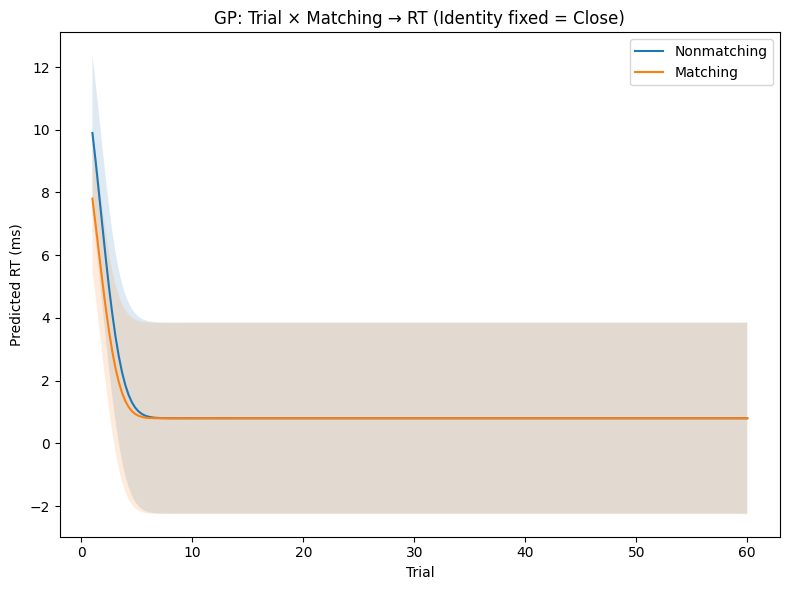

In [5]:
# ----------------------------
# ① Trial × Matching → RT
# ----------------------------
model.eval()
likelihood.eval()

identities = encoder.categories_[0]
identity_fix = identities[0]   # ← 固定 Identity（例如 Self）
matching_levels = [0, 1]

plt.figure(figsize=(8, 6))

for match in matching_levels:

    # 构建预测网格
    trial_range = np.linspace(1, df["Trial"].max(), 200)
    df_pred = pd.DataFrame({
        "Trial": trial_range,
        "Shape_Standardized_Identity": [identity_fix] * 200,
        "Matching_code": [match] * 200
    })

    # 自动 one-hot
    identity_pred_onehot = encoder.transform(
        df_pred[["Shape_Standardized_Identity"]]
    )

    X_pred = np.column_stack([
        df_pred["Trial"],
        identity_pred_onehot,
        df_pred["Matching_code"]
    ])

    X_pred_tensor = torch.tensor(X_pred, dtype=torch.float32)

    # GP prediction
    with torch.no_grad(), gpytorch.settings.fast_pred_var():
        pred = likelihood(model(X_pred_tensor))

    mean = pred.mean.numpy()
    std = pred.stddev.numpy()

    label_name = "Matching" if match == 1 else "Nonmatching"
    plt.plot(trial_range, mean, label=label_name)
    plt.fill_between(trial_range, mean-2*std, mean+2*std, alpha=0.15)

plt.xlabel("Trial")
plt.ylabel("Predicted RT (ms)")
plt.title(f"GP: Trial × Matching → RT (Identity fixed = {identity_fix})")
plt.legend()
plt.tight_layout()
plt.show()


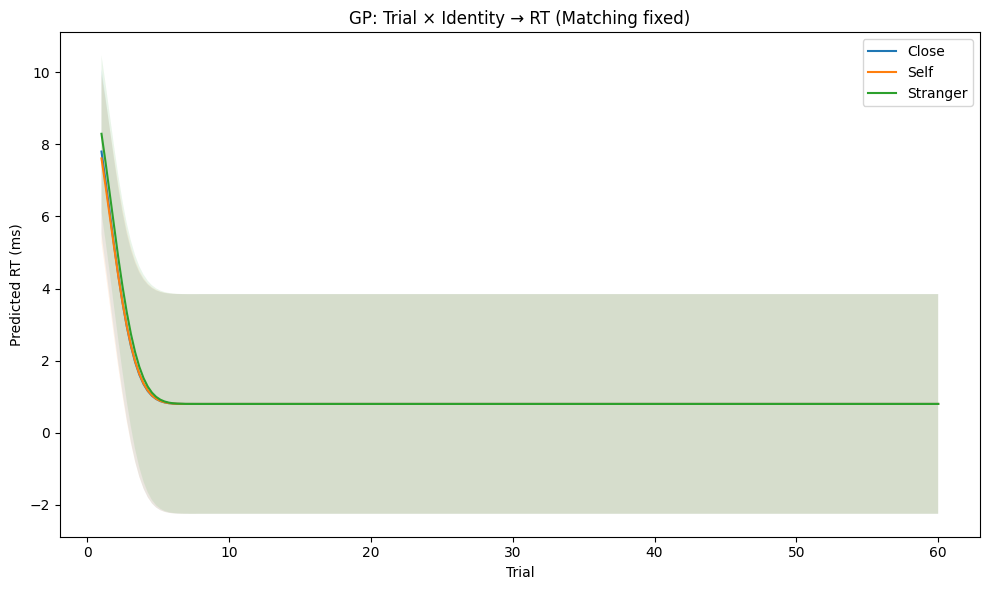

In [6]:
# ----------------------------
# ② Trial × Identity → RT
# ----------------------------
model.eval()
likelihood.eval()

identities = encoder.categories_[0]
match_fix = 1   # 固定为 Matching（你也可以设为 0）

plt.figure(figsize=(10, 6))

for id_name in identities:

    trial_range = np.linspace(1, df["Trial"].max(), 200)

    df_pred = pd.DataFrame({
        "Trial": trial_range,
        "Shape_Standardized_Identity": [id_name] * 200,
        "Matching_code": [match_fix] * 200
    })

    identity_pred_onehot = encoder.transform(
        df_pred[["Shape_Standardized_Identity"]]
    )

    X_pred = np.column_stack([
        df_pred["Trial"],
        identity_pred_onehot,
        df_pred["Matching_code"]
    ])

    X_pred_tensor = torch.tensor(X_pred, dtype=torch.float32)

    with torch.no_grad(), gpytorch.settings.fast_pred_var():
        pred = likelihood(model(X_pred_tensor))

    mean = pred.mean.numpy()
    std = pred.stddev.numpy()

    plt.plot(trial_range, mean, label=id_name)
    plt.fill_between(trial_range, mean-2*std, mean+2*std, alpha=0.1)

plt.xlabel("Trial")
plt.ylabel("Predicted RT (ms)")
plt.title("GP: Trial × Identity → RT (Matching fixed)")
plt.legend()
plt.tight_layout()
plt.show()
